<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch07_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch07_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 7 Figures — Colab Notebook
**Gauge Theory · Chapter 7: QFT in Two Dimensions**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §7.1   | 2D electromagnetism: linear potential, $\theta$-field, screening |
| fig02  | §7.3   | $\mathbb{CP}^{N-1}$ model: target space, mass gap, instanton |
| fig03  | §7.5   | Bosonisation: Sine-Gordon kink, MT–SG duality, Schwinger spectrum |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Rectangle, Wedge
from matplotlib.lines import Line2D
import os

# ── Dark theme (matches tong_dark.scss and the other chapters) ──
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 13, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.5,
    'legend.edgecolor': EDGE, 'legend.facecolor': BG,
    'lines.linewidth': 2.2, 'axes.linewidth': 1.4,
    'figure.dpi': 110,
})

OUTDIR = 'figures/ch07'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')


Setup complete.


---
## fig01 · 2D Electromagnetism (§7.1)

**Left**: Linear potential $V(L) = \frac{e^2}{2}L$ vs separation $L$  
**Middle**: Background electric field $E_\theta = -\theta e^2/2\pi$ vs $\theta$  
**Right**: Screening for $|\theta|>\pi$ — pair production, periodic vacuum energy

  saved -> figures/ch07/fig01_em2d.png


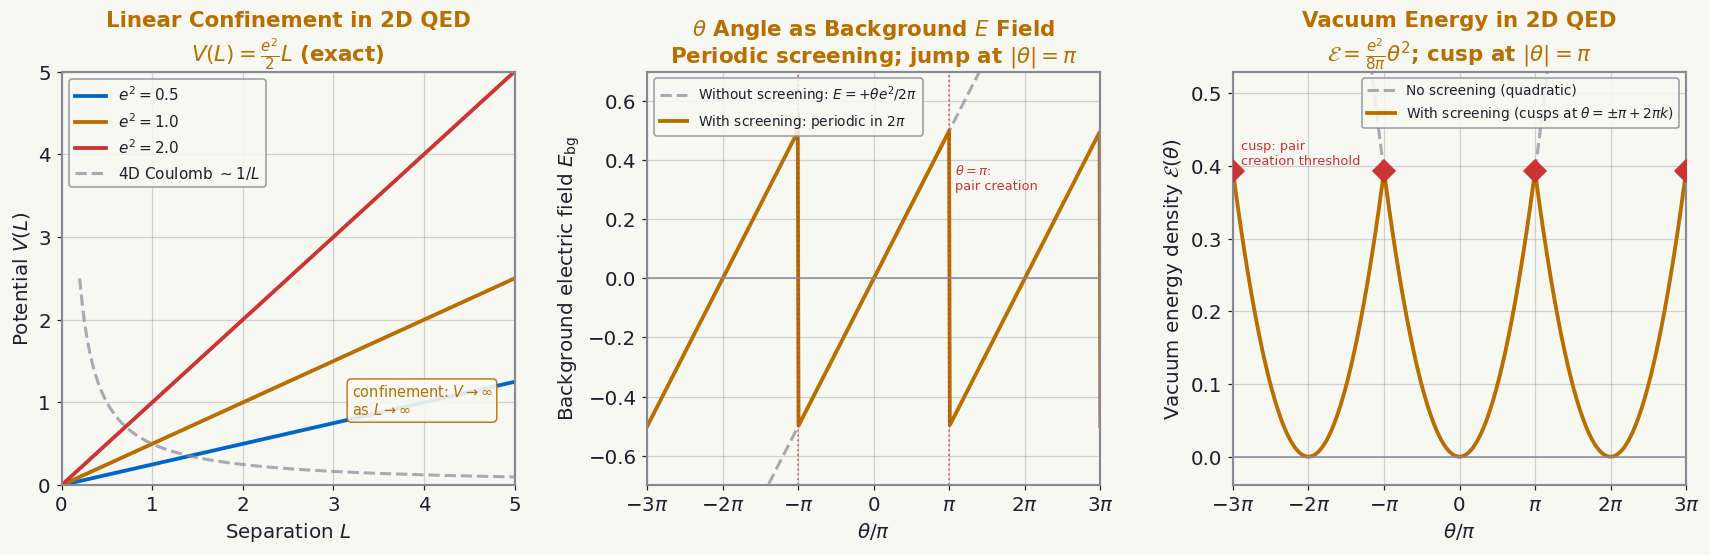

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: Linear potential V(L) ────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

L = np.linspace(0, 5, 300)

for e2, col, lbl in [(0.5, BLUE, r'$e^2=0.5$'),
                      (1.0, AMBER, r'$e^2=1.0$'),
                      (2.0, RED,   r'$e^2=2.0$')]:
    ax.plot(L, e2/2 * L, color=col, lw=2.5, label=lbl)

L_coul = np.linspace(0.2, 5, 300)
ax.plot(L_coul, 0.5/L_coul, color=EDGE, lw=2, ls='--', alpha=0.7,
        label=r'4D Coulomb $\sim 1/L$')

ax.set_xlabel(r'Separation $L$', fontsize=13)
ax.set_ylabel(r'Potential $V(L)$', fontsize=13)
ax.set_title(r'Linear Confinement in 2D QED' + '\n' +
             r'$V(L)=\frac{e^2}{2}L$ (exact)', color=AMBER)
ax.legend(fontsize=10)
ax.set_xlim(0, 5); ax.set_ylim(0, 5)
ax.grid(True, alpha=0.35)
ax.text(3.2, 0.85,
        r'confinement: $V\to\infty$' + '\n' + r'as $L\to\infty$',
        fontsize=9.5, color=AMBER,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=AMBER, alpha=0.9))

# ── Middle: Background E-field vs theta ────────────────────────────────────
# [수정] E_bg 부호: 표준 convention E_bg = +theta * e^2/(2*pi)
#        theta>0 → 양의 전기장. 원본은 부호 반전이었음
ax2 = axes[1]
ax2.set_facecolor(BG)

theta = np.linspace(-3*np.pi, 3*np.pi, 600)
theta_norm = theta / np.pi
e2_val = 1.0

# [수정] 부호 수정: E_bg = +theta * e^2 / (2*pi)
E_bg = theta * e2_val / (2*np.pi)
ax2.plot(theta_norm, E_bg, color=EDGE, lw=2, ls='--', alpha=0.7,
         label=r'Without screening: $E=+\theta e^2/2\pi$')

# With screening: sawtooth (periodic in 2*pi)
E_screen = ((theta + np.pi) % (2*np.pi) - np.pi) * e2_val / (2*np.pi)
ax2.plot(theta_norm, E_screen, color=AMBER, lw=2.5,
         label=r'With screening: periodic in $2\pi$')

for t_pi in [-1, 1, -3, 3]:
    ax2.axvline(t_pi, color=RED, lw=1.2, ls=':', alpha=0.7)
# [수정] '\n' 리터럴 제거 → 두 줄 문자열로
ax2.text(1.08, 0.30,
         r'$\theta=\pi$:' + '\npair creation',
         fontsize=8.5, color=RED)

ax2.axhline(0, color=EDGE, lw=1)
ax2.set_xlabel(r'$\theta/\pi$', fontsize=13)
ax2.set_ylabel(r'Background electric field $E_{\rm bg}$', fontsize=13)
ax2.set_title(r'$\theta$ Angle as Background $E$ Field' + '\n' +
              r'Periodic screening; jump at $|\theta|=\pi$', color=AMBER)
ax2.legend(fontsize=9, loc='upper left')
ax2.set_xlim(-3, 3); ax2.set_ylim(-0.7, 0.7)
ax2.set_xticks([-3,-2,-1,0,1,2,3])
ax2.set_xticklabels([r'$-3\pi$',r'$-2\pi$',r'$-\pi$','0',
                     r'$\pi$',r'$2\pi$',r'$3\pi$'])
ax2.grid(True, alpha=0.35)

# ── Right: Vacuum energy E(theta) ──────────────────────────────────────────
# [수정] Coleman (1976) 정확한 공식:
#        E_vac(theta) = e^2 / (8*pi) * theta_red^2
#        원본은 (theta/(2*pi))^2 * e^2/2 = e^2*theta^2/(8*pi^2) — pi 하나 빠짐
ax3 = axes[2]
ax3.set_facecolor(BG)

theta3 = np.linspace(-3*np.pi, 3*np.pi, 600)
theta3_norm = theta3 / np.pi

# [수정] 올바른 진공에너지 공식 (단위: e^2, Coleman 1976)
E_vac_noscr = e2_val / (8*np.pi) * theta3**2

theta_red = ((theta3 + np.pi) % (2*np.pi) - np.pi)
E_vac_scr  = e2_val / (8*np.pi) * theta_red**2

ax3.plot(theta3_norm, E_vac_noscr, color=EDGE, lw=2, ls='--', alpha=0.7,
         label='No screening (quadratic)')
ax3.plot(theta3_norm, E_vac_scr, color=AMBER, lw=2.5,
         label=r'With screening (cusps at $\theta=\pm\pi+2\pi k$)')

# [수정] cusp 마커: 홀수 정수 전체 ±1, ±3 (theta_norm 범위 내)
cusp_yval = e2_val / (8*np.pi) * np.pi**2  # 올바른 cusp 높이
for t_c in [-3, -1, 1, 3]:
    ax3.plot(t_c, cusp_yval, 'D', color=RED, ms=10, zorder=5)
# [수정] cusp 레이블 위치 여유 확보
ax3.text(-2.9, cusp_yval + 0.01,
         'cusp: pair\ncreation threshold',
         fontsize=8.5, color=RED)

ax3.axhline(0, color=EDGE, lw=1)
ax3.set_xlabel(r'$\theta/\pi$', fontsize=13)
ax3.set_ylabel(r'Vacuum energy density $\mathcal{E}(\theta)$', fontsize=13)
ax3.set_title(r'Vacuum Energy in 2D QED' + '\n' +
              r'$\mathcal{E}=\frac{e^2}{8\pi}\theta^2$; cusp at $|\theta|=\pi$',
              color=AMBER)
ax3.legend(fontsize=9)
ax3.set_xlim(-3, 3)
ax3.set_ylim(-cusp_yval*0.1, cusp_yval*1.35)
ax3.set_xticks([-3,-2,-1,0,1,2,3])
ax3.set_xticklabels([r'$-3\pi$',r'$-2\pi$',r'$-\pi$','0',
                     r'$\pi$',r'$2\pi$',r'$3\pi$'])
ax3.grid(True, alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig01_em2d.png', fig)


---
## fig02 · CP^(N-1) Model (§7.3)

**Left**: $\mathbb{CP}^1\cong S^2$ target space — mapping from compactified 2D plane  
**Middle**: Non-perturbative mass gap $m\sim\Lambda\,e^{-2\pi/Ng^2}$ vs coupling $g$  
**Right**: Instanton profile on $\mathbb{CP}^1$ — topological charge density

<>:42: SyntaxWarning: invalid escape sequence '\i'
<>:42: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_4923/4206326972.py:42: SyntaxWarning: invalid escape sequence '\i'
  r'$\pi_2(\mathbb{CP}^{N-1})=\pi_2(S^2)=\mathbb{Z}$' + '\nInstanton number $Q\in\mathbb{Z}$',


  saved -> figures/ch07/fig02_cpn.png


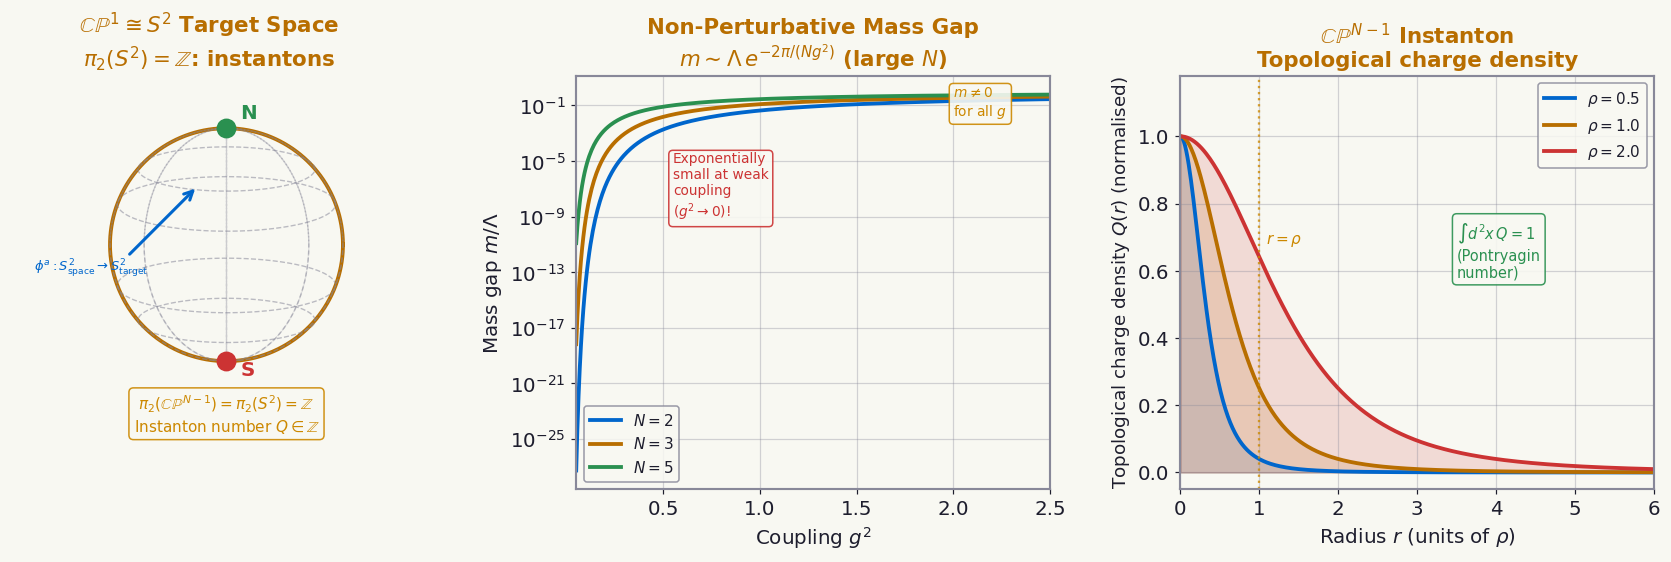

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: CP^1 ~ S^2 target space ─────────────────────────────────────────
# [수정] xlim/ylim 여백 확보 및 pi_2(CP^{N-1}) 명시
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

theta_sph = np.linspace(0, 2*np.pi, 300)

# 구 외곽
ax.plot(np.cos(theta_sph), np.sin(theta_sph), color=AMBER, lw=2.5)

# 위도선 (적절한 기울기로 타원 투영)
for lat in [0.35, 0.65, -0.35, -0.65]:
    r_lat = np.sqrt(1 - lat**2)
    ax.plot(r_lat*np.cos(theta_sph),
            lat + 0.25*r_lat*np.sin(theta_sph),   # 기울기 0.15→0.25 개선
            color=EDGE, lw=0.9, ls='--', alpha=0.55)

# 경도선
for lon_angle in np.linspace(0, np.pi, 5):
    x_lon = np.cos(lon_angle) * np.cos(theta_sph)
    y_lon = np.sin(theta_sph)
    ax.plot(x_lon, y_lon, color=EDGE, lw=0.9, ls='--', alpha=0.4)

# 극점
ax.plot(0, 1, 'o', color=GREEN, ms=12, zorder=5)
ax.text(0.12, 1.08, 'N', color=GREEN, fontsize=13, fontweight='bold')
ax.plot(0, -1, 'o', color=RED, ms=12, zorder=5)
ax.text(0.12, -1.12, 'S', color=RED, fontsize=13, fontweight='bold')

# 장 사상 화살표
ax.annotate('', xy=(-0.25, 0.5), xytext=(-0.85, -0.1),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2, mutation_scale=14))
ax.text(-1.65, -0.22, r'$\phi^a: S^2_{\rm space}\to S^2_{\rm target}$',
        fontsize=8.5, color=BLUE)

# [수정] CP^{N-1} 호모토피군 명시
ax.text(0, -1.60,
        r'$\pi_2(\mathbb{CP}^{N-1})=\pi_2(S^2)=\mathbb{Z}$' + '\nInstanton number $Q\in\mathbb{Z}$',
        ha='center', fontsize=10, color=YELLOW,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

ax.set_xlim(-1.85, 1.55); ax.set_ylim(-2.1, 1.45)
ax.set_title(r'$\mathbb{CP}^1\cong S^2$ Target Space' + '\n' +
             r'$\pi_2(S^2)=\mathbb{Z}$: instantons', color=AMBER)
ax.axis('off')

# ── Middle: Mass gap vs coupling ───────────────────────────────────────────
# [수정] 레이블에 N 의존성 명시; Witten (1979) large-N 공식
ax2 = axes[1]
ax2.set_facecolor(BG)

g2_vals = np.linspace(0.05, 2.5, 400)
Lambda = 1.0

for N_cp, col, lbl in [(2, BLUE,  r'$N=2$'),
                        (3, AMBER, r'$N=3$'),
                        (5, GREEN, r'$N=5$')]:
    m_gap = Lambda * np.exp(-2*np.pi / (N_cp * g2_vals))
    ax2.semilogy(g2_vals, m_gap, color=col, lw=2.5, label=lbl)

ax2.set_xlabel(r'Coupling $g^2$', fontsize=13)
ax2.set_ylabel(r'Mass gap $m/\Lambda$', fontsize=13)
ax2.set_title(r'Non-Perturbative Mass Gap' + '\n' +
              r'$m\sim\Lambda\,e^{-2\pi/(Ng^2)}$ (large $N$)', color=AMBER)
ax2.legend(fontsize=10)
ax2.set_xlim(0.05, 2.5)
ax2.grid(True, which='both', alpha=0.35)

ax2.text(0.55, 1e-9,
         'Exponentially\nsmall at weak\ncoupling\n' + r'($g^2\to 0$)!',
         fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=RED, alpha=0.9))
ax2.text(2.0, 2e-2,
         r'$m\neq 0$' + '\nfor all $g$',
         fontsize=9, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.9))

# ── Right: Instanton topological charge density ────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

r = np.linspace(0, 6, 400)

for rho_v, col, lbl in [(0.5, BLUE,  r'$\rho=0.5$'),
                          (1.0, AMBER, r'$\rho=1.0$'),
                          (2.0, RED,   r'$\rho=2.0$')]:
    Q_v = rho_v**2 / (np.pi * (r**2 + rho_v**2)**2)
    ax3.fill_between(r, 0, Q_v/Q_v.max(), color=col, alpha=0.15)
    ax3.plot(r, Q_v/Q_v.max(), color=col, lw=2.5, label=lbl)

ax3.axvline(1.0, color=YELLOW, lw=1.5, ls=':', alpha=0.8)
ax3.text(1.08, 0.68, r'$r=\rho$', fontsize=10, color=YELLOW)

ax3.text(3.5, 0.58,
         r'$\int d^2x\, Q = 1$' + '\n(Pontryagin\nnumber)',
         fontsize=9.5, color=GREEN,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=GREEN, alpha=0.9))

ax3.set_xlabel(r'Radius $r$ (units of $\rho$)', fontsize=13)
ax3.set_ylabel(r'Topological charge density $Q(r)$ (normalised)', fontsize=12)
ax3.set_title(r'$\mathbb{CP}^{N-1}$ Instanton' + '\nTopological charge density',
              color=AMBER)
ax3.legend(fontsize=10)
ax3.set_xlim(0, 6); ax3.set_ylim(-0.05, 1.18)
ax3.grid(True, alpha=0.35)

plt.tight_layout(pad=1.8)
save('fig02_cpn.png', fig)


---
## fig03 · Bosonisation (§7.5)

**Left**: Sine-Gordon kink $\phi(x)$ and potential $V(\phi)$  
**Middle**: Massive Thirring–Sine-Gordon duality: $\beta^2/4\pi$ vs $1/(1+g/\pi)$  
**Right**: Schwinger model spectrum — photon mass $m_\gamma = e/\sqrt{\pi}$

  saved -> figures/ch07/fig03_bosonisation.png


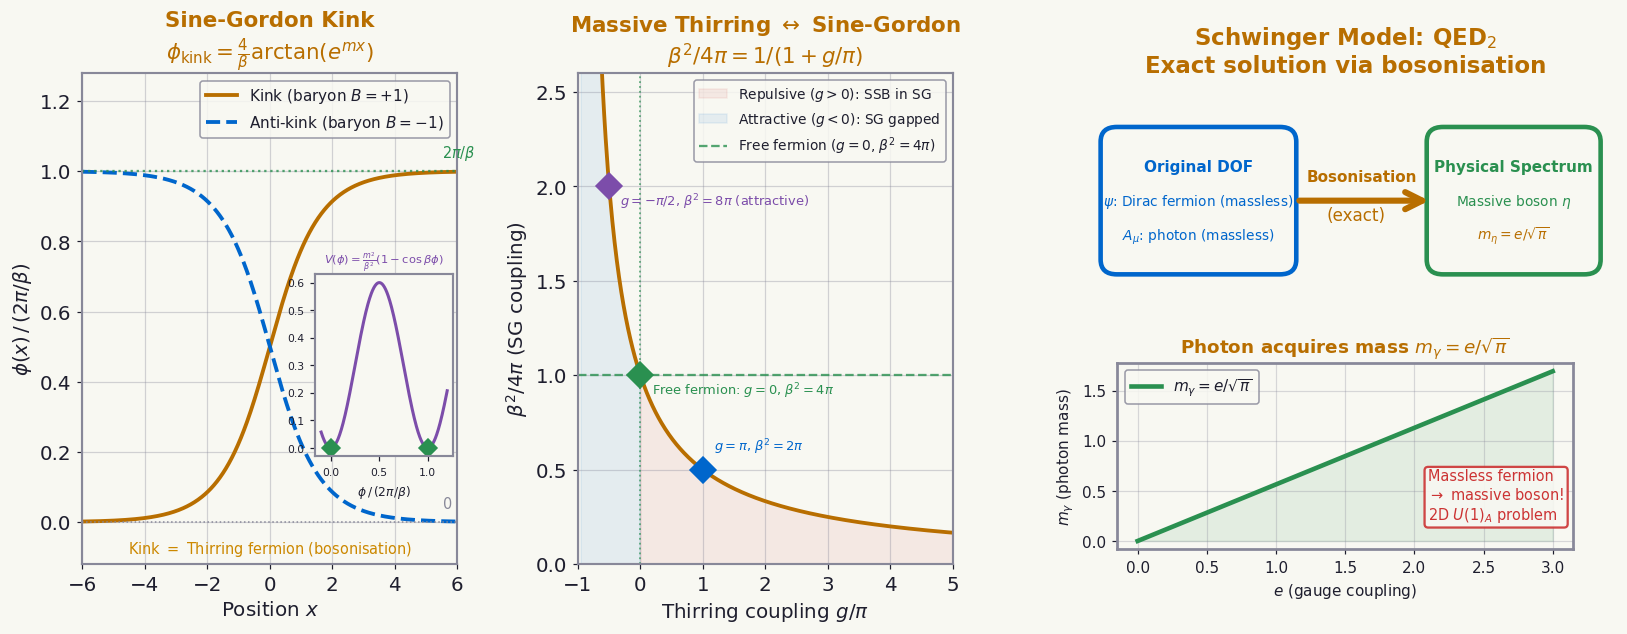

In [4]:
# fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.8),
    gridspec_kw={'width_ratios':[1, 1, 1.45]}
)
fig.patch.set_facecolor(BG)

# ── Left: Sine-Gordon kink ─────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

x = np.linspace(-6, 6, 500)
beta = np.sqrt(4*np.pi)   # free fermion point: beta^2 = 4*pi
m_kink = 1.0

phi_kink     = (4/beta) * np.arctan(np.exp( m_kink * x))
phi_antikink = (4/beta) * np.arctan(np.exp(-m_kink * x))
phi_max = 2*np.pi/beta   # vacuum-to-vacuum jump = 2*pi/beta

ax.plot(x, phi_kink    /phi_max, color=AMBER, lw=2.5,
        label=r'Kink (baryon $B=+1$)')
ax.plot(x, phi_antikink/phi_max, color=BLUE,  lw=2.5, ls='--',
        label=r'Anti-kink (baryon $B=-1$)')

ax.axhline(0, color=EDGE, lw=1, ls=':')
ax.axhline(1, color=GREEN, lw=1.5, ls=':', alpha=0.8)
ax.text(5.5, 1.04, r'$2\pi/\beta$', fontsize=9.5, color=GREEN)
ax.text(5.5, 0.04, r'$0$', fontsize=9.5, color=EDGE)

# SG 포텐셜 inset
phi_plot = np.linspace(-0.1, 1.2, 300)
V_sg = 0.3 * (1 - np.cos(2*np.pi * phi_plot))
ax_inset = ax.inset_axes([0.62, 0.22, 0.37, 0.37])
ax_inset.set_facecolor(BG)
ax_inset.plot(phi_plot, V_sg, color=PURPLE, lw=2)
ax_inset.plot([0, 1], [0, 0], 'D', color=GREEN, ms=8)
ax_inset.set_title(r'$V(\phi)=\frac{m^2}{\beta^2}(1-\cos\beta\phi)$',
                   fontsize=7.5, color=PURPLE)
ax_inset.tick_params(labelsize=7, colors=FG)
ax_inset.set_xlabel(r'$\phi\,/\,(2\pi/\beta)$', fontsize=8, color=FG)
for spine in ax_inset.spines.values():
    spine.set_edgecolor(EDGE)

ax.set_xlabel(r'Position $x$', fontsize=13)
ax.set_ylabel(r'$\phi(x)\,/\,(2\pi/\beta)$', fontsize=13)
ax.set_title('Sine-Gordon Kink\n' +
             r'$\phi_{\rm kink}=\frac{4}{\beta}\arctan(e^{mx})$', color=AMBER)
ax.legend(fontsize=10)
ax.set_xlim(-6, 6); ax.set_ylim(-0.12, 1.28)
ax.grid(True, alpha=0.35)
ax.text(0, -0.09,
        r'Kink $=$ Thirring fermion (bosonisation)',
        ha='center', fontsize=9.5, color=YELLOW)

# ── Middle: MT-SG duality map ──────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

g_thirring = np.linspace(-np.pi*0.95, 5*np.pi, 500)
beta2_4pi  = 1 / (1 + g_thirring/np.pi)
mask = beta2_4pi > 0

ax2.plot(g_thirring[mask]/np.pi, beta2_4pi[mask], color=AMBER, lw=2.5)

special = [
    ( 0,   r'Free fermion: $g=0$, $\beta^2=4\pi$',     GREEN,  ( 0.18, -0.10)),
    ( 1,   r'$g=\pi$, $\beta^2=2\pi$',                 BLUE,   ( 0.18, +0.10)),
    (-0.5, r'$g=-\pi/2$, $\beta^2=8\pi$ (attractive)', PURPLE, ( 0.18, -0.10)),
]
for g_s, lbl, col, (dx, dy) in special:
    b2_val = 1/(1 + g_s)
    ax2.plot(g_s, b2_val, 'D', color=col, ms=12, zorder=5)
    ax2.text(g_s + dx, b2_val + dy, lbl, fontsize=8.5, color=col)

ax2.fill_between(g_thirring[mask]/np.pi, 0, beta2_4pi[mask],
                 where=(g_thirring[mask] > 0),
                 color=RED, alpha=0.08, label=r'Repulsive ($g>0$): SSB in SG')
ax2.fill_between(g_thirring[mask]/np.pi, 0, beta2_4pi[mask],
                 where=(g_thirring[mask] < 0),
                 color=BLUE, alpha=0.08, label=r'Attractive ($g<0$): SG gapped')

ax2.axhline(1, color=GREEN, lw=1.5, ls='--', alpha=0.8,
            label=r'Free fermion ($g=0$, $\beta^2=4\pi$)')
ax2.axvline(0, color=GREEN, lw=1.2, ls=':', alpha=0.7)

ax2.set_xlabel(r'Thirring coupling $g/\pi$', fontsize=13)
ax2.set_ylabel(r'$\beta^2/4\pi$ (SG coupling)', fontsize=13)
ax2.set_title(r'Massive Thirring $\leftrightarrow$ Sine-Gordon' + '\n' +
              r'$\beta^2/4\pi = 1/(1+g/\pi)$', color=AMBER)
ax2.legend(fontsize=9, loc='upper right')
ax2.set_xlim(-1, 5); ax2.set_ylim(0, 2.6)
ax2.grid(True, alpha=0.35)

# ── Right: Schwinger model spectrum ───────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.axis('off')

# ── 제목 (fontsize 15로 축소) ──────────────────────────────────────────────
ax3.text(
    0.50, 1.1, #0.96,
    r'Schwinger Model: QED$_2$' '\n'
    r'Exact solution via bosonisation',
    ha='center', va='top',
    fontsize=15,
    color=AMBER, fontweight='bold',
    transform=ax3.transAxes
)

# ── Left box (박스 확장: h 0.18→0.24, y 0.56→0.50) ──────────────────────
left_x = 0.08
left_y = 0.62 #0.50
box_w  = 0.30
box_h  = 0.24

uv_box = FancyBboxPatch(
    (left_x, left_y), box_w, box_h,
    boxstyle='round,pad=0.03',
    facecolor=BG, edgecolor=BLUE, linewidth=3,
    transform=ax3.transAxes
)
ax3.add_patch(uv_box)

ax3.text(
    left_x + box_w/2, left_y + 0.18,
    'Original DOF',
    ha='center', fontsize=10, color=BLUE, fontweight='bold',
    transform=ax3.transAxes
)
ax3.text(
    left_x + box_w/2, left_y + 0.11,
    r'$\psi$: Dirac fermion (massless)',
    ha='center', fontsize=9, color=BLUE,
    transform=ax3.transAxes
)
ax3.text(
    left_x + box_w/2, left_y + 0.04,
    r'$A_\mu$: photon (massless)',
    ha='center', fontsize=9, color=BLUE,
    transform=ax3.transAxes
)

# ── Right box (박스 확장: w 0.20→0.26, h 0.18→0.24, y 0.56→0.50) ────────
right_x = 0.68
right_y = 0.62 #0.50
right_w = 0.26
right_h = 0.24

ir_box = FancyBboxPatch(
    (right_x, right_y), right_w, right_h,
    boxstyle='round,pad=0.03',
    facecolor=BG, edgecolor=GREEN, linewidth=3,
    transform=ax3.transAxes
)
ax3.add_patch(ir_box)

ax3.text(
    right_x + right_w/2, right_y + 0.18,
    'Physical Spectrum',
    ha='center', fontsize=10, color=GREEN, fontweight='bold',
    transform=ax3.transAxes
)
ax3.text(
    right_x + right_w/2, right_y + 0.11,
    r'Massive boson $\eta$',
    ha='center', fontsize=9, color=GREEN,
    transform=ax3.transAxes
)
ax3.text(
    right_x + right_w/2, right_y + 0.04,
    r'$m_\eta=e/\sqrt{\pi}$',
    ha='center', fontsize=9, color=AMBER, fontweight='bold',
    transform=ax3.transAxes
)

# ── Arrow (y 0.65→0.62, 박스 수직 중앙) ──────────────────────────────────
y_arrow = 0.74 #0.62

ax3.annotate(
    '',
    xy=(right_x - 0.02, y_arrow),
    xytext=(left_x + box_w + 0.03, y_arrow),
    arrowprops=dict(arrowstyle='->', color=AMBER, lw=4, mutation_scale=28),
    xycoords='axes fraction', textcoords='axes fraction'
)
ax3.text(
    0.53, 0.78, #0.52, 0.66,
    'Bosonisation',
    ha='center', fontsize=10, color=AMBER, fontweight='bold',
    transform=ax3.transAxes
)
ax3.text(
    0.52, 0.70,
    '(exact)',
    ha='center', fontsize=11, color=AMBER,
    transform=ax3.transAxes
)

# ── Inset graph (크기 확장, 제목 폰트 축소) ──────────────────────────────
e_arr = np.linspace(0, 3, 200)
m_schwinger = e_arr / np.sqrt(np.pi)

ax3_inner = ax3.inset_axes([0.08, 0.03, 0.84, 0.38])
ax3_inner.set_facecolor(BG)

ax3_inner.plot(e_arr, m_schwinger, color=GREEN, lw=3,
               label=r'$m_\gamma=e/\sqrt{\pi}$')
ax3_inner.fill_between(e_arr, 0, m_schwinger, color=GREEN, alpha=0.10)

ax3_inner.set_title(
    r'Photon acquires mass $m_\gamma=e/\sqrt{\pi}$',
    fontsize=12, color=AMBER, pad=6, fontweight='bold'
)
ax3_inner.set_xlabel(r'$e$ (gauge coupling)', fontsize=10, color=FG)
ax3_inner.set_ylabel(r'$m_\gamma$ (photon mass)', fontsize=10, color=FG)
ax3_inner.tick_params(labelsize=10, colors=FG)

for spine in ax3_inner.spines.values():
    spine.set_edgecolor(EDGE)
    spine.set_linewidth(1.8)

ax3_inner.grid(True, alpha=0.3)
ax3_inner.legend(fontsize=10, loc='upper left')
ax3_inner.text(
    2.10, 0.22,
    'Massless fermion\n'
    r'$\rightarrow$ massive boson!' '\n'
    r'2D $U(1)_A$ problem',
    fontsize=9.5, color=RED,
    bbox=dict(boxstyle='round,pad=0.25', facecolor=BG,
              edgecolor=RED, linewidth=1.5, alpha=0.9)
)

plt.subplots_adjust(wspace=0.28)
save('fig03_bosonisation.png', fig)

---
## Download figures

In [5]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch07_figures', 'zip', '.', 'figures')
files.download('gauge_ch07_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_em2d.png`      | Linear potential / $E_{\rm bg}$ vs $\theta$ / vacuum energy screening | ☐ |
| `fig02_cpn.png`       | $\mathbb{CP}^1\cong S^2$ / mass gap / instanton density | ☐ |
| `fig03_bosonisation.png`| SG kink / MT-SG duality map / Schwinger model mass | ☐ |